# Tarea-Práctica 4. Métodos de integración numérica
**Física Computacional, grupo 8270**

Alumna: Irma Alexia Dezotti Apantenco

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import scipy.special
import scipy.integrate

## 1. Regla del trapecio

### (a)
Primero leo los datos del archivo, la primera columna es el tiempo y la segunda la velocidad.

In [66]:
datos = np.loadtxt("velocidades.txt")
t = datos[:,0]
v = datos[:,1]

print(t[0:6])
print(v[0:6])

[0. 1. 2. 3. 4. 5.]
[0.       0.069478 0.137694 0.204332 0.269083 0.331656]


Para la distancia uso la regla del trapecio pero acumulando, o sea la distancia al tiempo $t_i$ es la integral de 0 a $t_i$.
Como los datos estan cada segundo, $h = 1$ y cada trapecio vale $\frac{h}{2}(v_{i-1}+v_i)$.

In [67]:
h = t[1] - t[0]   # deberia ser 1

x = np.zeros(len(t))   # aqui guardo la distancia
x[0] = 0

for i in range(1, len(t)):
    trapecio = h/2 * (v[i-1] + v[i])
    x[i] = x[i-1] + trapecio

print("distancia en t = 100 s:", x[-1], "m")

distancia en t = 100 s: 8.218924000000003 m


### (b)

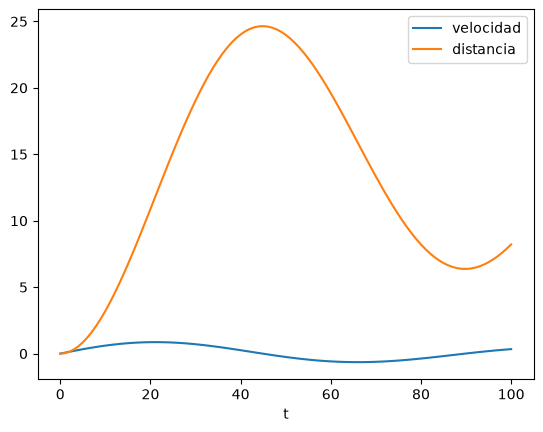

In [68]:
plt.plot(t, v, label="velocidad")
plt.plot(t, x, label="distancia")
plt.xlabel("t")
plt.legend()
plt.show()

Se ve que la distancia sube cuando la velocidad es positiva y baja cuando es negativa (la particula se regresa), y los maximos de la distancia estan donde la velocidad cruza el cero.

## 2. Límite de difracción de un telescopio

### (a)
Hago la funcion de Bessel con la regla de Simpson:
$$\int_a^b f(\theta)d\theta \approx \frac{h}{3}\left[f(a)+f(b)+4\sum_{impares} f + 2\sum_{pares} f\right]$$
con N = 1000 (tiene que ser par).

In [69]:
def J(m, x):
    N = 1000
    a = 0
    b = np.pi
    h = (b - a)/N

    def f(theta):
        return np.cos(m*theta - x*np.sin(theta))

    suma = f(a) + f(b)
    for k in range(1, N):
        if k % 2 == 1:
            suma = suma + 4*f(a + k*h)
        else:
            suma = suma + 2*f(a + k*h)

    integral = h/3 * suma
    return integral / np.pi

# prueba: J0(0) deberia dar 1
print(J(0, 0))
print(J(1, 0))

1.0000000000000002
-1.9243865760169383e-18


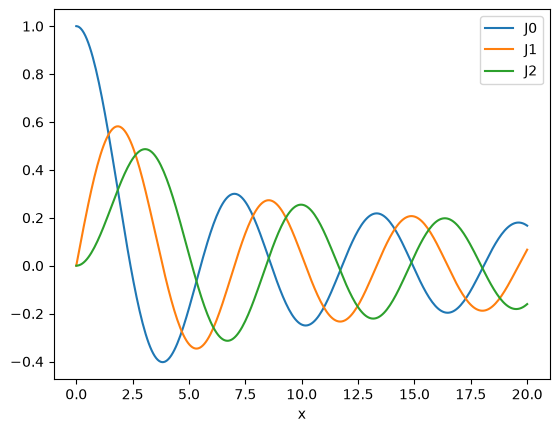

In [70]:
xs = np.linspace(0, 20, 300)

J0 = []
J1 = []
J2 = []
for xx in xs:
    J0.append(J(0, xx))
    J1.append(J(1, xx))
    J2.append(J(2, xx))

plt.plot(xs, J0, label="J0")
plt.plot(xs, J1, label="J1")
plt.plot(xs, J2, label="J2")
plt.xlabel("x")
plt.legend()
plt.show()

### (b)
Ahora lo hago con `scipy.integrate.simpson`, le doy los puntos de theta y los valores de la funcion.

In [71]:
def J_scipy(m, x):
    theta = np.linspace(0, np.pi, 1001)   # 1001 puntos = 1000 intervalos
    y = np.cos(m*theta - x*np.sin(theta))
    return sp.integrate.simpson(y, x=theta) / np.pi

dif0 = []
dif1 = []
dif2 = []
for xx in xs:
    dif0.append(abs(J(0, xx) - J_scipy(0, xx)))
    dif1.append(abs(J(1, xx) - J_scipy(1, xx)))
    dif2.append(abs(J(2, xx) - J_scipy(2, xx)))

print("diferencia maxima J0:", max(dif0))
print("diferencia maxima J1:", max(dif1))
print("diferencia maxima J2:", max(dif2))

diferencia maxima J0: 2.7755575615628914e-15
diferencia maxima J1: 1.2212453270876722e-15
diferencia maxima J2: 1.4432899320127035e-15


La diferencia es del orden de $10^{-15}$ o menos, o sea son practicamente iguales (lo que queda es error de redondeo de la computadora). 

Tambien lo compare con la funcion `sp.special.jv` que ya trae scipy para ver que si estuviera bien:

In [72]:
print("mi J1(5)     =", J(1, 5))
print("scipy jv(1,5)=", sp.special.jv(1, 5))

mi J1(5)     = -0.32757913759146534
scipy jv(1,5)= -0.3275791375914652


### (c)
Para la grafica de densidad hago una malla de puntos (x, y) en el plano focal de -1 µm a 1 µm, calculo $r=\sqrt{x^2+y^2}$ y la intensidad.
Cuando r = 0 no puedo dividir entre cero, entonces uso el hint: $J_1(x)/x \to 1/2$, entonces $I(0) = 1/4$.

In [73]:
lam = 500e-9          # 500 nm
k = 2*np.pi/lam

def I(r):
    if r == 0:
        return 0.25
    return (J(1, k*r) / (k*r))**2

n = 100                       # puntos por lado (si pongo mas tarda mucho)
lado = 1e-6                   # 1 micra
xg = np.linspace(-lado, lado, n)
yg = np.linspace(-lado, lado, n)

intensidad = np.zeros([n, n])
for i in range(n):
    for j in range(n):
        r = np.sqrt(xg[j]**2 + yg[i]**2)
        intensidad[i, j] = I(r)

print("listo")

listo


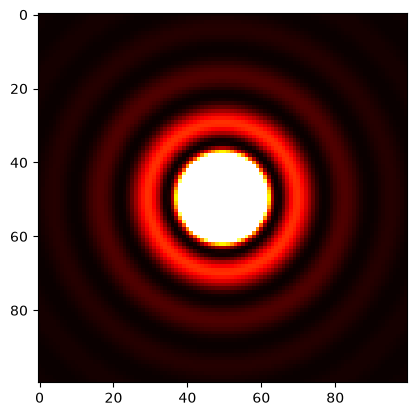

In [81]:
# con vmax pequeña se ven mejor los anillos porque el centro es muy brillante
plt.imshow(intensidad, cmap="hot", vmax=0.01)
plt.show()

## 3. Capacidad calorífica de un sólido

### (a)
Uso la cuadratura gaussiana como en clase, con `roots_legendre` que me da los puntos $x_i$ y los pesos $w_i$ en el intervalo [-1, 1].
Como mi integral va de 0 a $\theta_D/T$ tengo que cambiar los puntos al intervalo [a, b]:
$$x_i' = \frac{b-a}{2}x_i + \frac{b+a}{2}, \qquad w_i' = \frac{b-a}{2}w_i$$

In [44]:
def IntegralW(f, a, b, N):
    I = 0
    L = sp.special.roots_legendre(N)

    for i in range(len(L[0])):
        x = L[0][i]
        w = L[1][i]
        # cambio de intervalo de [-1,1] a [a,b]
        xp = (b - a)/2 * x + (b + a)/2
        wp = (b - a)/2 * w
        I = I + wp * f(xp)
    return I

# prueba: la integral de x^2 de 0 a 3 es 9
print(IntegralW(lambda x: x**2, 0, 3, 50))

9.000000000000027


In [45]:
V = 1000e-6          # 1000 cm^3 en m^3
rho = 6.022e28       # m^-3
thetaD = 428         # K
kB = 1.380649e-23    # J/K

def integrando(x):
    return x**4 * np.exp(x) / (np.exp(x) - 1)**2

def Cv(T):
    integral = IntegralW(integrando, 0, thetaD/T, 50)
    return 9*V*rho*kB * (T/thetaD)**3 * integral

print("Cv(300 K) =", Cv(300), "J/K")

Cv(300 K) = 2257.7973049455954 J/K


### (b)

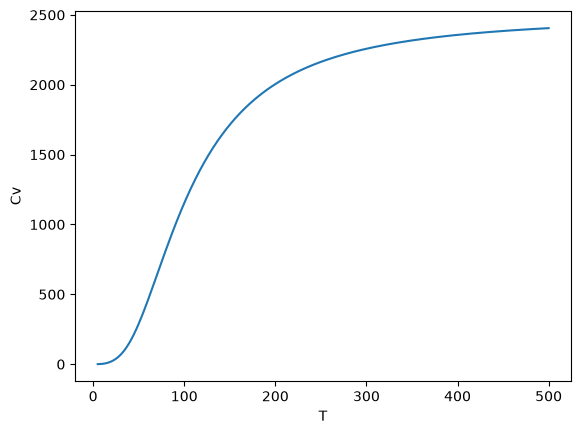

valor clasico 3NkB = 2494.2804834000003


In [46]:
temps = np.linspace(5, 500, 200)
C = []
for T in temps:
    C.append(Cv(T))

plt.plot(temps, C)
plt.xlabel("T")
plt.ylabel("Cv")
plt.show()

print("valor clasico 3NkB =", 3*V*rho*kB)

A temperaturas bajas $C_V$ crece como $T^3$ y a temperaturas altas se aplana y tiende al valor clasico $3Nk_B$ (ley de Dulong-Petit), que da como 2490 J/K.

## 4. Incertidumbre cuántica en el oscilador armónico

### (a)
Para no tener que calcular todos los polinomios cada vez con recursion (que se tardaria muchisimo para n grande), uso un for que va guardando solo los dos ultimos.

In [47]:
def H(n, x):
    if n == 0:
        return 1 + 0*x     # el 0*x es para que regrese un arreglo si x es arreglo
    if n == 1:
        return 2*x
    h0 = 1 + 0*x
    h1 = 2*x
    for k in range(1, n):
        h2 = 2*x*h1 - 2*k*h0
        h0 = h1
        h1 = h2
    return h1

def psi(n, x):
    c = 1/np.sqrt(2**n * factorial(n) * np.sqrt(np.pi))
    return c * np.exp(-x**2/2) * H(n, x)

# pruebas: H2(1) = 4-2 = 2, H3(1) = 8-12 = -4
print(H(2, 1), H(3, 1))

2 -4


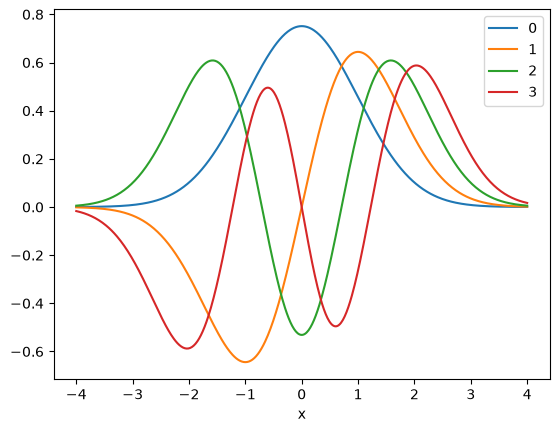

In [48]:
x = np.linspace(-4, 4, 500)

for n in range(4):
    plt.plot(x, psi(n, x), label=n)

plt.xlabel("x")
plt.legend()
plt.show()

### (b)

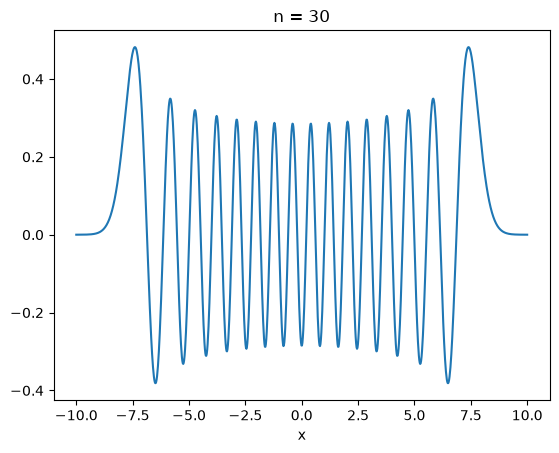

tardo 0.07770800590515137 segundos


In [49]:
import time
inicio = time.time()

x = np.linspace(-10, 10, 1000)
plt.plot(x, psi(30, x))
plt.xlabel("x")
plt.title("n = 30")
plt.show()

print("tardo", time.time() - inicio, "segundos")

### (c)
La integral va de $-\infty$ a $\infty$, entonces hago el cambio de variable
$$x = \frac{z}{1-z^2}, \qquad dx = \frac{1+z^2}{(1-z^2)^2}dz$$
y asi queda de -1 a 1, que es justo el intervalo de la cuadratura gaussiana.

In [50]:
def incertidumbre(n):
    N = 100
    L = sp.special.roots_legendre(N)
    suma = 0
    for i in range(N):
        z = L[0][i]
        w = L[1][i]
        x = z/(1 - z**2)
        dx = (1 + z**2)/(1 - z**2)**2
        suma = suma + w * x**2 * abs(psi(n, x))**2 * dx
    return np.sqrt(suma)

print("incertidumbre para n = 5:", incertidumbre(5))

incertidumbre para n = 5: 2.3452078737858204


Sale aproximadamente 2.345, que es cercano a 2.3 como dice el problema. (Teoricamente $\langle x^2\rangle = n + 1/2 = 5.5$ y $\sqrt{5.5} = 2.345$, entonces si esta bien.)

## 5. Atracción gravitacional de una lámina uniforme

### (a)
Tomo un pedacito de la lamina de area $dx\,dy$ en la posicion $(x, y, 0)$. Su masa es $dm = \sigma\, dx\, dy$.
La masa de 1 kg esta en $(0, 0, z)$, entonces la distancia entre los dos es
$$d = \sqrt{x^2 + y^2 + z^2}$$
La fuerza de ese pedacito es (ley de Newton con $m = 1$ kg)
$$dF = \frac{G\, dm}{d^2} = \frac{G\sigma\, dx\, dy}{x^2+y^2+z^2}$$
y apunta hacia el pedacito. Solo me interesa la componente en z, que es la fuerza por el coseno del angulo con el eje z, $\cos\phi = z/d$:
$$dF_z = \frac{G\sigma\, dx\, dy}{x^2+y^2+z^2}\cdot\frac{z}{\sqrt{x^2+y^2+z^2}} = G\sigma z\frac{dx\, dy}{(x^2+y^2+z^2)^{3/2}}$$
(las componentes en x y en y se cancelan por simetria). Sumando sobre toda la lamina, de $-L/2$ a $L/2$ en x y en y:
$$F_z = G\sigma z\int\int_{-L/2}^{L/2}\frac{dx\, dy}{(x^2+y^2+z^2)^{3/2}}$$

### (b)
$\sigma$ = masa / area = 10000 kg / 100 m² = 100 kg/m².

In [51]:
G = 6.674e-11
L = 10            # m
M = 10000         # kg (10 toneladas)
sigma = M / L**2

def Fz(z):
    N = 100
    raices = sp.special.roots_legendre(N)
    xs = raices[0]
    ws = raices[1]
    a = -L/2
    b = L/2
    suma = 0
    for i in range(N):
        for j in range(N):
            x = (b - a)/2 * xs[i] + (b + a)/2
            y = (b - a)/2 * xs[j] + (b + a)/2
            wi = (b - a)/2 * ws[i]
            wj = (b - a)/2 * ws[j]
            suma = suma + wi*wj / (x**2 + y**2 + z**2)**(3/2)
    return G * sigma * z * suma

print("F(1 m) =", Fz(1), "N")

F(1 m) = 3.450590156038923e-08 N


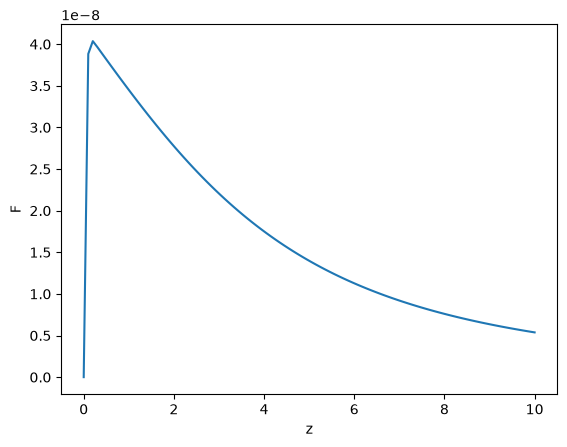

In [52]:
zs = np.linspace(0, 10, 100)
F = []
for z in zs:
    F.append(Fz(z))

plt.plot(zs, F)
plt.xlabel("z")
plt.ylabel("F")
plt.show()

### (c)
Cuando z es muy chiquito, la funcion $\frac{1}{(x^2+y^2+z^2)^{3/2}}$ se vuelve un pico muy alto y muy delgado justo en el centro (x = 0, y = 0), su ancho es mas o menos z.
La cuadratura usa 100 puntos fijos en cada eje, y si la separacion entre puntos es mas grande que el ancho del pico, los puntos "no ven" el pico y la integral sale mucho mas chica de lo que deberia. Ademas se multiplica por z que tiende a 0, entonces la fuerza se va a cero. Pero en realidad para una lamina cerca de su centro la fuerza deberia tender a $2\pi G\sigma$ (como un plano infinito).

Para arreglarlo (o que sea menor el error) se puede:
- usar mas puntos de muestra (asi el pico se nota para z mas chicos), aunque tarda mas.
- dividir la lamina en pedazos y poner mas puntos cerca del centro, que es donde esta el pico.
- o hacer un cambio de variable (por ejemplo a polares) para que el integrando no sea tan picudo.

Por ejemplo con 200 puntos la caida se hace mas angosta (y ya casi llega a $2\pi G\sigma$ que es como 4.2e-8):

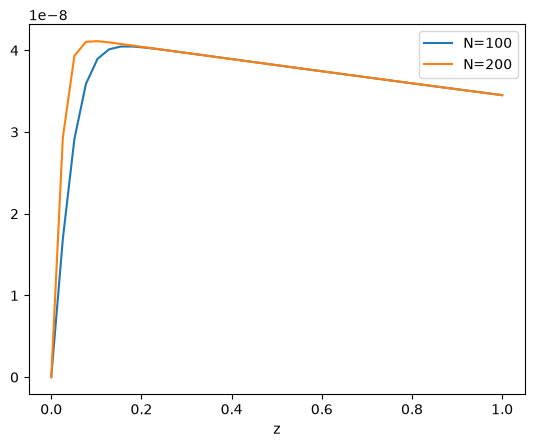

In [53]:
# copie la funcion de arriba pero con N de parametro
def Fz2(z, N):
    raices = sp.special.roots_legendre(N)
    xs = raices[0]
    ws = raices[1]
    a = -L/2
    b = L/2
    suma = 0
    for i in range(N):
        for j in range(N):
            x = (b - a)/2 * xs[i] + (b + a)/2
            y = (b - a)/2 * xs[j] + (b + a)/2
            wi = (b - a)/2 * ws[i]
            wj = (b - a)/2 * ws[j]
            suma = suma + wi*wj / (x**2 + y**2 + z**2)**(3/2)
    return G * sigma * z * suma

zs2 = np.linspace(0, 1, 40)
F100 = []
F200 = []
for z in zs2:
    F100.append(Fz2(z, 100))
    F200.append(Fz2(z, 200))

plt.plot(zs2, F100, label="N=100")
plt.plot(zs2, F200, label="N=200")
plt.xlabel("z")
plt.legend()
plt.show()

## 6. Rejillas de difracción

### (a)
$\sin^2(\alpha u)$ vale cero cuando $\alpha u = n\pi$, o sea en $u = n\pi/\alpha$, y entre dos ceros hay un maximo (una "rendija").
Entonces la separacion entre rendijas es el periodo de $\sin^2$:
$$d = \frac{\pi}{\alpha}$$

### (b)
Si $d = 20\,\mu m$ entonces $\alpha = \pi/d$.

In [54]:
d = 20e-6
alfa = np.pi / d

def q(u):
    return np.sin(alfa*u)**2

print(q(0), q(10e-6))   # en 0 no pasa luz, en 10 micras pasa toda

0.0 1.0


### (c)
Datos: 10 rendijas, entonces $w = 10 \times 20\,\mu m = 200\,\mu m$, $\lambda = 500$ nm, $f = 1$ m, la pantalla va de x = -5 cm a 5 cm.

Use la regla de Simpson porque es facil y el integrando es suave (no tiene picos raros). Para escoger N me fije en que el integrando oscila: $\sqrt{q(u)}$ tiene 10 "jorobas" y la exponencial $e^{i2\pi xu/\lambda f}$ en la orilla de la pantalla da $\frac{x w}{\lambda f} = \frac{0.05\cdot 200\times10^{-6}}{500\times10^{-9}} = 20$ vueltas.
O sea en total unas 30 oscilaciones, y necesito varios puntos por cada oscilacion para que la integral salga bien, entonces con N = 1000 sobra. Tambien influye cuanto tiempo tarda, porque hay que hacer la integral para cada punto de la pantalla.

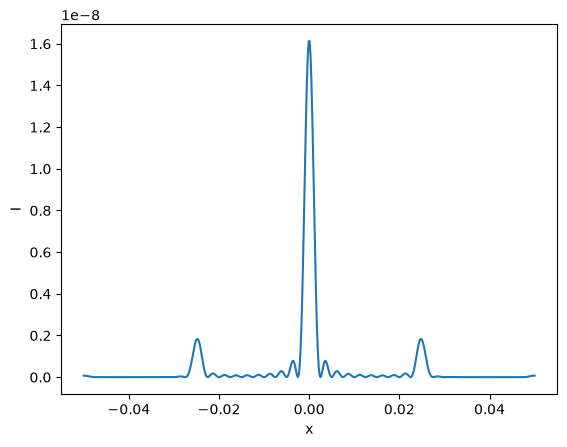

In [87]:
lam = 500e-9
f = 1
w = 10 * d

def I_rejilla(x, qfun, a, b, N=1000):
    # regla de simpson con numeros complejos
    h = (b - a)/N
    def g(u):
        return np.sqrt(qfun(u)) * np.exp(1j*2*np.pi*x*u/(lam*f))
    suma = g(a) + g(b)
    for k in range(1, N):
        if k % 2 == 1:
            suma = suma + 4*g(a + k*h)
        else:
            suma = suma + 2*g(a + k*h)
    integral = h/3 * suma
    return abs(integral)**2

xpant = np.linspace(-0.05, 0.05, 500)
Ix = []
for xx in xpant:
    Ix.append(intensidad(xx, q, -w/2, w/2))

plt.plot(xpant, Ix)
plt.xlabel("x")
plt.ylabel("I")
plt.show()

Salen picos en x = 0 y en ±2.5 cm, que coincide con $x = \lambda f/d = 500\times10^{-9}/20\times10^{-6} = 2.5$ cm.

### (d)
Para que parezca la pantalla repito la misma fila muchas veces hacia abajo y la grafico con `imshow`.

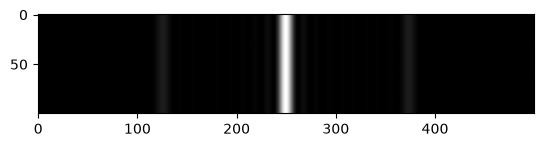

In [83]:
imagen = np.array([Ix] * 100)    # 100 filas iguales
plt.imshow(imagen, cmap="gray")
plt.show()

### (e)
**i.** $q(u) = \sin^2(\alpha u)\sin^2(\beta u)$ con $\beta = \alpha/2$

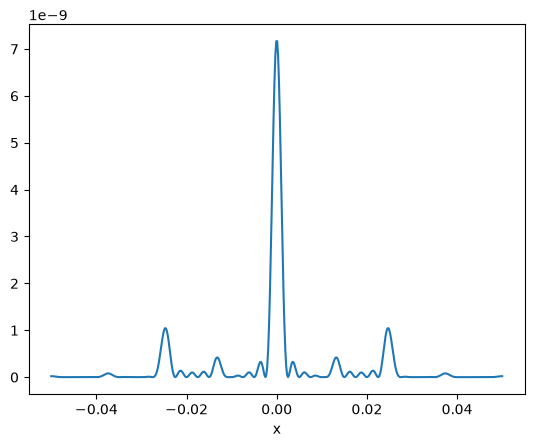

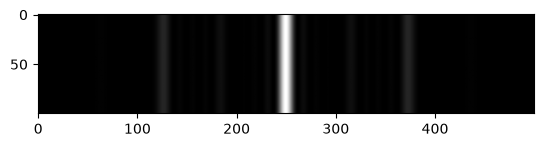

In [88]:
beta = alfa/2

def q2(u):
    return np.sin(alfa*u)**2 * np.sin(beta*u)**2

I2 = []
for xx in xpant:
    I2.append(I_rejilla(xx, q2, -w/2, w/2))

plt.plot(xpant, I2)
plt.xlabel("x")
plt.show()

imagen2 = np.array([I2] * 100)
plt.imshow(imagen2, cmap="gray")
plt.show()

**ii.** Dos rendijas cuadradas, una de 10 µm y otra de 20 µm con 60 µm entre ellas. Las acomode asi (en micras):
rendija 1 de -45 a -35, hueco de -35 a 25, rendija 2 de 25 a 45. Entonces integro de -45 a 45.

Como q(u) brinca de 0 a 1 de golpe, aqui use mas puntos (N = 4000) para que los brincos queden bien.

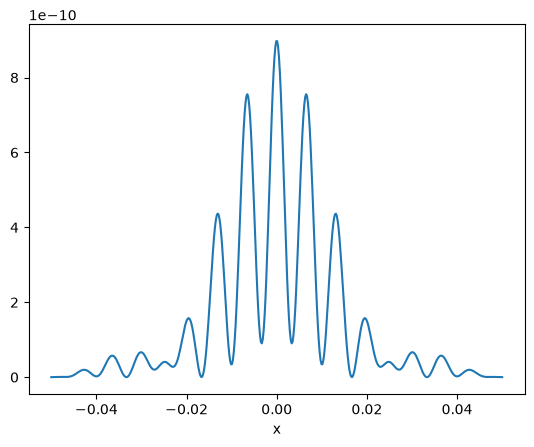

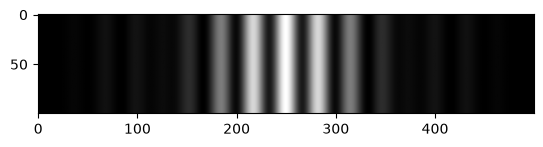

In [89]:
def q3(u):
    if u >= -45e-6 and u <= -35e-6:
        return 1
    elif u >= 25e-6 and u <= 45e-6:
        return 1
    else:
        return 0

I3 = []
for xx in xpant:
    I3.append(I_rejilla(xx, q3, -45e-6, 45e-6, N=4000))

plt.plot(xpant, I3)
plt.xlabel("x")
plt.show()

imagen3 = np.array([I3] * 100)
plt.imshow(imagen3, cmap="gray")
plt.show()